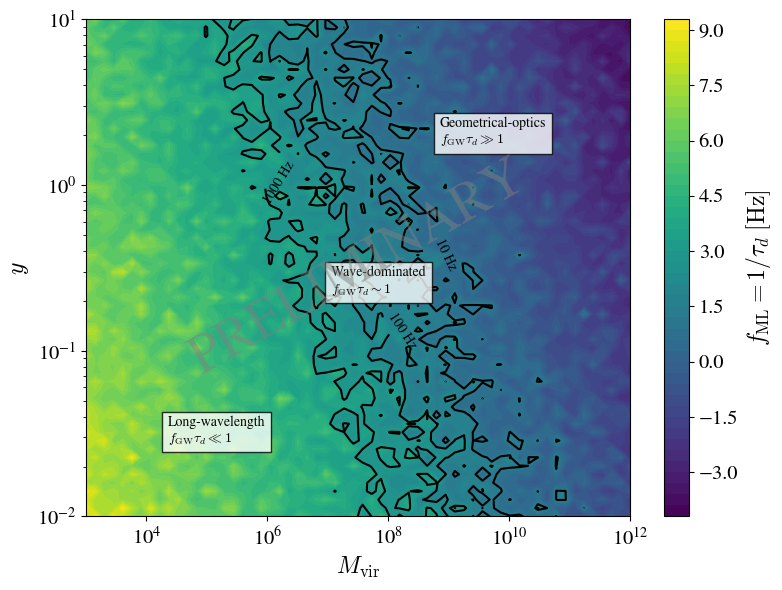

In [67]:
import numpy as np
from gwlens.lens import nfw
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from gwlens.tools import halo
import astropy.units as u
from glow import time_domain_c, freq_domain_c, lenses
from gwlens.lens import nfw
import astropy.units as u

#from lens_amplification.nfw.int_1d_nfw_parallel import F_grid


plotting.apply_figure_style()

#input parameters
lens_virial_mass = np.logspace(3, 12, 60) #This should be the x-axis 
impact_parameter = np.logspace(-2, 1.0, 60) #This should be the y-axis
lens_redshift = 1.0
source_redshift = 2.0

#meshgrid for impact parameter and lens mass
M_virial,Y = np.meshgrid(lens_virial_mass,impact_parameter)

TD_grid = np.zeros_like(M_virial) 

for i in range(M_virial.shape[0]):
    for j in range(M_virial.shape[1]):
        
        lens_virial_mass = M_virial[i,j]
        impact_parameter = Y[i,j]
        #NFW-normalizations
        Halo =halo.NFW(M200=lens_virial_mass,zl=lens_redshift)
        k_values = np.array(Halo.scaling_ratio(zs=source_redshift))
        effective_redshifted_lensmass = np.array(Halo.mass_enclosed_at_xrs(1.0).value * (1 + lens_redshift))



        nfw_lens = nfw.NFW1()
        #TD = nfw_lens.Time_Delay(y1=impact_parameter,y2=0, rs=k_values,Ml=effective_redshifted_lensmass)
        TD = nfw_lens.Time_Delay(y1=impact_parameter,y2=0,rs=k_values,Ml=effective_redshifted_lensmass)
                # convert to seconds
        TD_sec = np.array([
            t.to_value(u.s)
            for t in TD
        ])

        dt21 = TD_sec[2] - TD_sec[1]

        TD_grid[i, j] = dt21

#TD = np.array([
#    [t.to_value(u.s) for t in row]
#    for row in TD
#]) * u.s
#dt12 = TD[:,1] - TD[:,0]
#dt23 = TD[:,2] - TD[:,1]
F_grid = 1.0 / TD_grid  # Hz


fig, ax = plt.subplots(figsize=(8,6))

contour = ax.contourf(
    M_virial,
    Y,
    np.log10(F_grid),
    levels=50
)

cbar = plt.colorbar(contour)
cbar.set_label(r'$f_{\text{ML}} = 1/\tau_d \; [\mathrm{Hz}]$')

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlabel(r'$M_{\rm vir}$')
ax.set_ylabel(r'$y$')

# -----------------------
# regime boundary lines
# f_GW * tau_d = 1
# -----------------------
freqs = [10, 100, 1000]  # Hz (like paper)

CS_list = []

freqs = [10, 100, 1000]

for f in freqs:
    CS = ax.contour(
        M_virial,
        Y,
        f * TD_grid,
        levels=[1],
        colors='black',
        linewidths=1.5
    )

    ax.clabel(
        CS,
        inline=True,
        fontsize=10,
        fmt={1: f"{f} Hz"},
        inline_spacing=5
    )

    CS_list.append(CS)

# -----------------------
# regime annotations
# -----------------------
ax.text(0.15, 0.15, "Long-wavelength\n$f_{\\text{GW}} \\tau_d \\ll 1$",
        transform=ax.transAxes,
        bbox=dict(facecolor='white', alpha=0.8))

ax.text(0.65, 0.75, "Geometrical-optics\n$f_{\\text{GW}} \\tau_d \\gg 1$",
        transform=ax.transAxes,
        bbox=dict(facecolor='white', alpha=0.8))

ax.text(0.45, 0.45, "Wave-dominated\n$f_{\\text{GW}} \\tau_d \\sim 1$",
        transform=ax.transAxes,
        bbox=dict(facecolor='white', alpha=0.8))




ax.text(
    0.5, 0.5,
    "PRELIMINARY",
    transform=ax.transAxes,
    fontsize=40,
    color='gray',
    alpha=0.5,
    ha='center',
    va='center',
    rotation=30
)

plt.tight_layout()
plt.show()

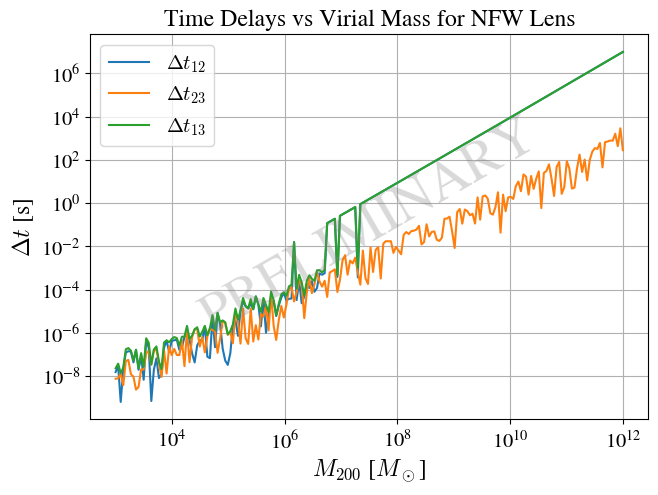

In [44]:
dt12 = TD[:,1] - TD[:,0]
dt23 = TD[:,2] - TD[:,1]
dt13 = TD[:,2] - TD[:,0]
plt.loglog(lens_virial_mass, dt12, label=r'$\Delta t_{12}$')
plt.loglog(lens_virial_mass, dt23, label=r'$\Delta t_{23}$')
plt.loglog(lens_virial_mass, dt13, label=r'$\Delta t_{13}$')
plt.text(
    0.5, 0.5,
    "PRELIMINARY",
    transform=plt.gca().transAxes,
    fontsize=40,
    color='gray',
    alpha=0.3,
    ha='center',
    va='center',
    rotation=30
)
plt.xlabel(r'$M_{200}$ [$M_\odot$]')
plt.ylabel(r'$\Delta t$ [s]')
plt.title('Time Delays vs Virial Mass for NFW Lens')
plt.legend()
plt.grid()